# iEEI vs. dT/dt — Three-Layer Energy Balance Model at 2035
### Atmosphere · Upper Ocean (0–200 m) · Lower Ocean (>200 m)

This notebook uses the full three-layer model from **`WorkingModel.ipynb`** (same constants,
temperature-dependent albedo, CO₂-dependent emissivity and real CO₂ record) to ask:

> *Given the state of the climate system in 2035, how fast would the atmosphere and the
> ocean be warming for a given Earth energy imbalance?*

**Base state.** The model is spun up from pre-industrial equilibrium $[T_0, T_0, T_0]$ in
1850 to **2035** under SSP2-4.5 with no SAI. That gives the "current" layer temperatures
$T_a, T_u, T_l$ and the model's own 2035 energy imbalance $Q_{2035}$.

**iEEI.** The imposed Earth energy imbalance — the net top-of-atmosphere flux into the
system [W/m²]. It replaces the radiative term $R = S(1-\alpha_{net}) - \varepsilon\sigma T_a^4$
in the atmospheric equation:

$$C_a\frac{dT_a}{dt} = \mathrm{iEEI} - \gamma_{au}(T_a - T_u)$$
$$C_u\frac{dT_u}{dt} = \gamma_{au}(T_a - T_u) - \gamma_{ul}(T_u - T_l),
\qquad C_l\frac{dT_l}{dt} = \gamma_{ul}(T_u - T_l)$$

iEEI is swept from **0 to 1 W/m²**. For each value it is held fixed for one year starting
from the 2035 state, and the year-mean warming rate of the atmosphere and of the whole
ocean is plotted against it.


In [1]:
%matplotlib inline
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    # 'axes.grid': True,
    # 'grid.alpha': 0.3,
    'font.size': 11,
})

In [2]:
# == Analysis settings ========================================================
SPINUP_START_YEAR = 1850       # pre-industrial equilibrium year (start of the CO2 record)
BASE_YEAR         = 2035       # year whose state defines the "current" climate
SCENARIO          = 'ssp245'   # CO2 pathway for the 1850 -> BASE_YEAR spin-up

IEEI_MIN, IEEI_MAX, N_IEEI = -0.2, 1.2, 101   # iEEI sweep [W/m2]

## Model (copied from `WorkingModel.ipynb`)

The two cells below are taken unchanged from `WorkingModel.ipynb` (physical constants,
albedo, emissivity, layer heat capacities, coupling coefficients, and the CO₂ record), so
any change to the working model's parameters should be copied here too.

In [3]:
# == Physical constants =======================================================
S0     = 1361.0   # Solar constant [W/m2]
S      = S0 / 4   # Sphere-averaged mean insolation [W/m2]
SIGMA  = 5.670374419e-8   # Stefan-Boltzmann constant [W/m2/K4]

# == Pre-industrial baseline (1850) ===========================================
T0     = 288.15   # Surface temperature [K]  (~15 C)

# == Temperature-dependent earth albedo =======================================
# Budyko-style linear ice-albedo parameterization,  alpha_earth(T) = A - B*T,
# with T the ATMOSPHERIC temperature in KELVIN: colder -> more snow/ice cover ->
# higher albedo.  Clipped to a physically meaningful range (ice-free floor,
# snowball ceiling); over 1850-2100 the clip should never engage.
ALBEDO_A   = 1.82      # intercept [-]
ALBEDO_B   = 0.00526   # slope [1/K]  ->  d(alpha_earth)/dT = -0.00526 /K
ALBEDO_MIN = 0.15      # ice-free lower bound
ALBEDO_MAX = 0.65      # snowball upper bound


def alpha_earth(T):
    """Temperature-dependent earth albedo [-] (surface + non-SAI atmosphere)."""
    return np.clip(ALBEDO_A - ALBEDO_B * np.asarray(T, dtype=float),
                   ALBEDO_MIN, ALBEDO_MAX)[()]


def alpha_net(T, alpha_sai=0.0):
    """
    Total system albedo with a purely scattering SAI layer above the surface.

    Any energy the earth absorbs must be transmitted through the aerosol layer
    at least once (transmission 1 - alpha_SAI, no aerosol absorption assumed).
    It can then be reflected by the surface and scattered back down by the layer
    any number of times, each round trip carrying probability
    alpha_earth*alpha_SAI.  Summing that infinite geometric series,

        P_abs = (1-alpha_earth)(1-alpha_SAI) * sum_n (alpha_earth*alpha_SAI)^n
              = (1-alpha_earth)(1-alpha_SAI) / (1 - alpha_earth*alpha_SAI),

    and the system albedo is the reflected complement, alpha_net = 1 - P_abs.

    NOTE this is NOT alpha_earth + alpha_SAI.  The multiple reflections recover
    part of the light the aerosol layer scatters back upward, so a given
    alpha_SAI buys noticeably less than its face value in planetary
    reflectance (e.g. alpha_SAI = 0.015 at T0 raises alpha_net by only ~0.007).
    """
    a_e = alpha_earth(T)
    a_s = np.clip(np.asarray(alpha_sai, dtype=float), 0.0, 0.999)[()]
    return 1.0 - (1.0 - a_e) * (1.0 - a_s) / (1.0 - a_e * a_s)


def absorbed_sw(T, alpha_sai=0.0):
    """Absorbed shortwave flux  S*(1 - alpha_net)  [W/m2]."""
    return S * (1.0 - alpha_net(T, alpha_sai))


def alpha_sai_for_absorbed_sw(T, R_target):
    """
    Invert alpha_net(): the SAI-layer albedo that makes the absorbed shortwave
    equal R_target [W/m2] at temperature T.  Solving

        A = (1-a_e)(1-x) / (1 - a_e*x)   for x,   A = R_target/S

    gives the closed form

        x = [(1-a_e) - A] / [(1-a_e) - A*a_e].

    Clipped to [0, 0.999): SAI can only ADD reflective aerosol, so a negative
    solution (the target already absorbs less than the bare earth would) means
    no injection.
    """
    a_e   = float(alpha_earth(T))
    A     = R_target / S
    denom = (1.0 - a_e) - A * a_e
    if denom <= 0.0:
        return 0.0
    return float(np.clip(((1.0 - a_e) - A) / denom, 0.0, 0.999))


alpha0 = float(alpha_earth(T0))   # pre-industrial planetary albedo = alpha_earth(T0), no SAI

# == CO2 -> emissivity: Myhre et al. (1998) logarithmic forcing =============
CO2_0 = 280.0     # pre-industrial CO2 concentration [ppm]
K_CO2 = 5.35      # log-CO2 forcing coefficient [W/m2]

# OLR = eps(CO2) * SIGMA * Ta^4 ; eps0 is set so that CO2=CO2_0 gives T_eq = T0 exactly.
OLR0 = S * (1 - alpha0)          # required pre-industrial OLR [W/m2]  (alpha0 = alpha_earth(T0))
EPS0 = OLR0 / (SIGMA * T0**4)    # pre-industrial effective atmospheric emissivity [-]

# == Layer heat capacities ====================================================
# Ocean layer:  C = rho * c_p * h * f_ocean / (seconds per year)   [W.yr/m2/K]
# Atmosphere :  C = c_p_air * p_s / g       / (seconds per year)
RHO_W      = 1025.0     # seawater density [kg/m3]
CP_W       = 3990.0     # seawater heat capacity [J/kg/K]
F_OCEAN    = 0.71       # ocean fraction of Earth's surface
CP_AIR     = 1004.0     # air heat capacity [J/kg/K]
P_SURF     = 1.01325e5  # surface pressure [Pa]
G_GRAV     = 9.81       # gravity [m/s2]
SEC_PER_YR = 3.1557e7

UPPER_DEPTH = 200.0     # upper-ocean thickness [m]
LOWER_DEPTH = 3500.0    # lower-ocean thickness [m]  (ocean below 200 m; mean depth ~3700 m)

def ocean_layer_C(depth_m, f_ocean=F_OCEAN):
    '''Heat capacity per m2 of Earth for an ocean layer [W.yr/m2/K].'''
    return RHO_W * CP_W * depth_m * f_ocean / SEC_PER_YR

C_ATMOS = CP_AIR * P_SURF / G_GRAV / SEC_PER_YR     # atmospheric column
C_UPPER = ocean_layer_C(UPPER_DEPTH)                # fast (upper) ocean layer
C_LOWER = ocean_layer_C(LOWER_DEPTH)                # slow (deep) ocean layer

# == Inter-layer heat-exchange coefficients [W/m2/K] ==========================
GAMMA_AU = 5.0   # atmosphere <-> upper ocean (10 = strong air-sea coupling)
GAMMA_UL = 0.7    # upper <-> lower ocean (deep-ocean heat-uptake efficiency; Geoffroy 2013)

B_PLANCK = 4 * EPS0 * SIGMA * T0**3   # Planck feedback at T0, for comparison to the
                                       # tuned b=2.09 W/m2/K slope in the linear-OLR models

print(f"Pre-industrial OLR = {OLR0:.3f} W/m2  ->  eps0 = {EPS0:.4f}")
print(f"Planck feedback at T0:  4*eps0*sigma*T0^3 = {B_PLANCK:.3f} W/m2/K  "
      f"(cf. tuned b = 2.09 W/m2/K in the linear-OLR models)")
print(f"Heat capacities [W.yr/m2/K]:  C_a = {C_ATMOS:.3f}   C_u = {C_UPPER:.2f}   C_l = {C_LOWER:.1f}")
print(f"Response timescales:  atmosphere ~ {C_ATMOS/(B_PLANCK+GAMMA_AU):.3f} yr   "
      f"upper ocean ~ {C_UPPER/GAMMA_UL:.0f} yr   deep ocean ~ {C_LOWER/GAMMA_UL:.0f} yr")
print(f"Equilibrium check  ->  T_eq = {(OLR0/(EPS0*SIGMA))**0.25:.4f} K  (target: {T0} K)")
print(f"Albedo:  alpha_earth(T0) = {alpha0:.4f}   (slope {-ALBEDO_B:+.5f} /K, clipped to "
      f"[{ALBEDO_MIN}, {ALBEDO_MAX}])")
print(f"  shortwave (ice-albedo) feedback  S*B = {S*ALBEDO_B:.3f} W/m2/K  ->  net feedback "
      f"{B_PLANCK - S*ALBEDO_B:.3f} W/m2/K  (vs. {B_PLANCK:.3f} with a fixed albedo)")
print(f"  SAI example: alpha_SAI = 0.015 at T0  ->  alpha_net = {alpha_net(T0, 0.015):.4f} "
      f"(a rise of {alpha_net(T0, 0.015) - alpha0:.4f}, not 0.0150)")


Pre-industrial OLR = 236.701 W/m2  ->  eps0 = 0.6055
Planck feedback at T0:  4*eps0*sigma*T0^3 = 3.286 W/m2/K  (cf. tuned b = 2.09 W/m2/K in the linear-OLR models)
Heat capacities [W.yr/m2/K]:  C_a = 0.329   C_u = 18.40   C_l = 322.1
Response timescales:  atmosphere ~ 0.040 yr   upper ocean ~ 26 yr   deep ocean ~ 460 yr
Equilibrium check  ->  T_eq = 288.1500 K  (target: 288.15 K)
Albedo:  alpha_earth(T0) = 0.3043   (slope -0.00526 /K, clipped to [0.15, 0.65])
  shortwave (ice-albedo) feedback  S*B = 1.790 W/m2/K  ->  net feedback 1.496 W/m2/K  (vs. 3.286 with a fixed albedo)
  SAI example: alpha_SAI = 0.015 at T0  ->  alpha_net = 0.3116 (a rise of 0.0073, not 0.0150)


In [4]:
# Real CO2 data, replacing any synthetic linear-ramp / RCP-forcing approximation:
#
#   1850-1978 : Meinshausen et al. (2017) / CMIP6 historical GHG
#               concentrations (RCMIP "historical" series).
#   1979-2023 : NOAA GML observed global annual-mean CO2 -- real
#               measurements, not a reconstruction.
#   2024-2100 : RCMIP/CMIP6 SSP concentration pathway for the chosen
#               scenario (SSP1-2.6 / SSP2-4.5 / SSP5-8.5), offset-anchored
#               to the actual 2023 observed value so each projection
#               continues smoothly from real data instead of jumping to
#               RCMIP's (decade-old, slightly higher) projected 2023 value.
#
# See data/co2_historical_1850_2023.csv and data/co2_ssp_scenarios_2024_2100.csv
# (built from https://zenodo.org/records/4589756 and
# https://gml.noaa.gov/ccgg/trends/gl_data.html).
DATA_DIR = None
for _candidate in [pathlib.Path("data"), pathlib.Path("../data")]:
    if (_candidate / "co2_historical_1850_2023.csv").exists():
        DATA_DIR = _candidate
        break
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find data/co2_historical_1850_2023.csv -- run this notebook "
        "from the 'code' directory it lives in (or alongside a sibling 'data' folder)."
    )

SSP_SCENARIOS = ['ssp126', 'ssp245', 'ssp585']


def _load_co2_data():
    hist = np.genfromtxt(DATA_DIR / "co2_historical_1850_2023.csv", delimiter=",", skip_header=1)
    ssp  = np.genfromtxt(DATA_DIR / "co2_ssp_scenarios_2024_2100.csv", delimiter=",", skip_header=1)
    hist_years, hist_ppm = hist[:, 0], hist[:, 1]
    ssp_years = ssp[:, 0]
    ssp_cols  = {'ssp126': ssp[:, 1], 'ssp245': ssp[:, 2], 'ssp585': ssp[:, 3]}

    years_by_scenario, ppm_by_scenario = {}, {}
    for name in SSP_SCENARIOS:
        years_by_scenario[name] = np.concatenate([hist_years, ssp_years])
        ppm_by_scenario[name]   = np.concatenate([hist_ppm, ssp_cols[name]])
    return years_by_scenario, ppm_by_scenario


_CO2_YEARS, _CO2_PPM = _load_co2_data()


# Derived "hold" scenarios: follow a base SSP pathway until switch_year, then
# hold CO2 fixed at held_ppm from switch_year onward (a step change if held_ppm
# differs from the pathway value at switch_year).  name -> (base, switch_year, held_ppm)
_CO2_HOLDS = {}


def register_co2_hold(name, base_scenario, switch_year, held_ppm):
    '''Register a scenario that follows base_scenario, then holds CO2 at held_ppm from switch_year.'''
    _CO2_HOLDS[name] = (base_scenario, switch_year, float(held_ppm))
    return name


def co2_ppm(t, scenario='ssp245'):
    '''
    Atmospheric CO2 concentration [ppm] -- real historical record spliced
    with a real SSP concentration pathway (see module docstring above).
    'none' is a pre-industrial control: CO2 held at CO2_0 for all t.
    Names registered with register_co2_hold() follow their base pathway and
    then hold CO2 fixed from their switch year.
    '''
    if scenario == 'none':
        return CO2_0
    if scenario in _CO2_HOLDS:
        base, switch_year, held_ppm = _CO2_HOLDS[scenario]
        return np.where(np.asarray(t) >= switch_year, held_ppm, co2_ppm(t, base))[()]
    return np.interp(t, _CO2_YEARS[scenario], _CO2_PPM[scenario])


# Named hold scenario: SSP2-4.5 until 2035, then CO2 steps back to its 1850
# (pre-industrial record) value and is held there through 2100.
register_co2_hold('revert1850', 'ssp245', 2035, co2_ppm(1850, 'ssp245'))


def co2_forcing(t, scenario='ssp245'):
    '''
    CO2 radiative forcing relative to pre-industrial [W/m2], via the
    Myhre et al. (1998) logarithmic formula applied to the real CO2 record
    from co2_ppm() (rather than an independently-fit forcing curve).
    '''
    if scenario == 'none':
        return 0.0
    return K_CO2 * np.log(co2_ppm(t, scenario=scenario) / CO2_0)


def emissivity(CO2):
    '''
    Effective atmospheric emissivity: decreases (atmosphere becomes more
    IR-opaque) as CO2 rises above CO2_0. Vectorized over CO2.
    '''
    return EPS0 - K_CO2 * np.log(CO2 / CO2_0) / (SIGMA * T0**4)


In [5]:
def net_toa_imbalance(t, Ta, scenario=SCENARIO):
    '''Model's own net TOA flux, S*(1 - alpha_net(Ta)) - eps(CO2(t))*sigma*Ta^4  [W/m2] (no SAI).'''
    return S * (1 - alpha_net(Ta, 0.0)) - emissivity(co2_ppm(t, scenario=scenario)) * SIGMA * Ta**4


def layer_derivs(y, R, C_a=C_ATMOS, C_u=C_UPPER, C_l=C_LOWER,
                 gamma_au=GAMMA_AU, gamma_ul=GAMMA_UL):
    '''
    Three-layer tendencies [K/yr] for state y = [T_a, T_u, T_l] and a given net
    TOA flux R into the atmosphere [W/m2].  Same equations as WorkingModel.ipynb.
    '''
    Ta, Tu, Tl = y
    f_au = gamma_au * (Ta - Tu)   # atmosphere -> upper ocean
    f_ul = gamma_ul * (Tu - Tl)   # upper ocean -> lower ocean
    return np.array([(R - f_au) / C_a,
                     (f_au - f_ul) / C_u,
                     f_ul / C_l])


# == Spin-up: pre-industrial equilibrium (1850) -> BASE_YEAR, no SAI =============
spinup = solve_ivp(lambda t, y: layer_derivs(y, net_toa_imbalance(t, y[0])),
                   (SPINUP_START_YEAR, BASE_YEAR), [T0, T0, T0],
                   method='BDF', rtol=1e-8, atol=1e-10)
y_base = spinup.y[:, -1]
Ta_b, Tu_b, Tl_b = y_base
Q_base = net_toa_imbalance(BASE_YEAR, Ta_b)

print(f"{BASE_YEAR} state ({SCENARIO}, no SAI, spun up from {SPINUP_START_YEAR}):")
print(f"  T_a = {Ta_b:.3f} K  (dT = {Ta_b - T0:+.3f})   T_u = {Tu_b:.3f} K  (dT = {Tu_b - T0:+.3f})"
      f"   T_l = {Tl_b:.3f} K  (dT = {Tl_b - T0:+.3f})")
print(f"  CO2 = {co2_ppm(BASE_YEAR, SCENARIO):.1f} ppm   model EEI Q = {Q_base:.3f} W/m2")
print(f"  air->upper ocean flux  gamma_au*(Ta-Tu) = {GAMMA_AU*(Ta_b - Tu_b):.3f} W/m2")
print(f"  upper->lower ocean flux gamma_ul*(Tu-Tl) = {GAMMA_UL*(Tu_b - Tl_b):.3f} W/m2")

2035 state (ssp245, no SAI, spun up from 1850):
  T_a = 289.306 K  (dT = +1.156)   T_u = 289.128 K  (dT = +0.978)   T_l = 288.256 K  (dT = +0.106)
  CO2 = 455.9 ppm   model EEI Q = 0.897 W/m2
  air->upper ocean flux  gamma_au*(Ta-Tu) = 0.892 W/m2
  upper->lower ocean flux gamma_ul*(Tu-Tl) = 0.610 W/m2


## One-year-mean tendencies with iEEI held fixed

Each iEEI is held fixed as the net TOA flux for one year starting from the 2035 state, and
the year-mean rate $\overline{dT/dt} = [T(2036) - T(2035)]/1\,\mathrm{yr}$ is reported for
the atmosphere and the whole ocean. The whole-ocean rate is the heat-capacity-weighted
mean of the two ocean layers, $\dot T_o = (C_u\dot T_u + C_l\dot T_l)/(C_u + C_l)$.

A year is used rather than the instantaneous tendency because the atmosphere's response
time ($C_a/\gamma_{au} \approx$ weeks) is far shorter than a year: it relaxes to
$T_a \approx T_u + \mathrm{iEEI}/\gamma_{au}$ within weeks, after which the extra flux
reaches the ocean, so both rates depend on iEEI. (Instantaneously, the ocean tendency
would not depend on iEEI at all, since only the atmosphere exchanges radiation with space.)

The two rates differ by about an order of magnitude, so each has its own y-axis
(atmosphere left, ocean right), with the zeros aligned. Vertical lines mark the model's
own 2035 imbalance $Q_{2035}$ and the iEEI at which the atmosphere's year-mean
$dT_a/dt = 0$.

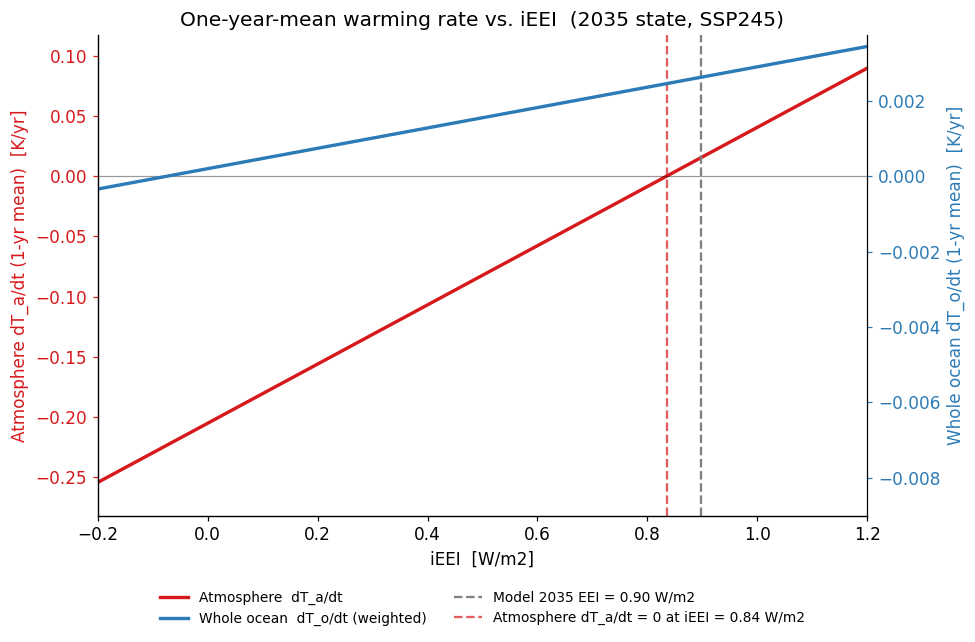

Year-mean dT_a/dt = 0 at iEEI = 0.835 W/m2  (model 2035 EEI = 0.897 W/m2);  whole-ocean dT_o/dt there = 2.453 mK/yr


In [6]:
ieei = np.linspace(IEEI_MIN, IEEI_MAX, N_IEEI)


def year_mean_dTdt(R, y0=y_base, years=1.0):
    '''Mean dT/dt [K/yr] for each layer over `years`, holding the net TOA flux at R.'''
    sol = solve_ivp(lambda t, y: layer_derivs(y, R), (0.0, years), y0,
                    method='BDF', rtol=1e-8, atol=1e-10)
    return (sol.y[:, -1] - y0) / years


dTdt_yr = np.array([year_mean_dTdt(x) for x in ieei])
dTa_yr, dTu_yr, dTl_yr = dTdt_yr.T
dTo_yr = (C_UPPER * dTu_yr + C_LOWER * dTl_yr) / (C_UPPER + C_LOWER)

# iEEI at which the atmosphere's year-mean dT_a/dt = 0 (root-find on the full model;
# the bracket is widened so the root is found even if it lies outside the sweep)
ieei_atm0 = brentq(lambda x: year_mean_dTdt(x)[0], -5.0, 5.0, xtol=1e-8)

ATM_COLOR, OCN_COLOR = '#d7191c', '#2c7bb6'


def _limits_with_zero(y, pad=0.08):
    '''(lo, hi) spanning y and 0, padded by `pad` of the range.'''
    lo, hi = min(np.min(y), 0.0), max(np.max(y), 0.0)
    span = (hi - lo) or max(abs(hi), 1e-6)
    return lo - pad * span, hi + pad * span


def _align_zeros(ax_l, ax_r, y_l, y_r):
    '''Set both y-limits so that y = 0 sits at the same height on each axis.'''
    (l0, l1), (r0, r1) = _limits_with_zero(y_l), _limits_with_zero(y_r)
    f = max(-l0 / (l1 - l0), -r0 / (r1 - r0))   # fraction of the axis below zero
    l0, r0 = -f / (1 - f) * l1, -f / (1 - f) * r1
    if l1 <= 0 or r1 <= 0:                      # all-negative data: anchor on the bottom instead
        l0, r0 = _limits_with_zero(y_l)[0], _limits_with_zero(y_r)[0]
        l1, r1 = l0 * -(1 - f) / f, r0 * -(1 - f) / f
    ax_l.set_ylim(l0, l1)
    ax_r.set_ylim(r0, r1)


def plot_twin_dTdt(dTa, dTo, title, ylabel_suffix='', ieei_atm0=None):
    '''Atmosphere dT/dt (left axis) and whole-ocean dT/dt (right axis) vs. iEEI.'''
    fig, ax = plt.subplots(figsize=(9, 6))
    ax2 = ax.twinx()
    ax2.grid(False)
    ax2.spines['right'].set_visible(True)

    ln_a = ax.plot(ieei, dTa, color=ATM_COLOR, lw=2.2, label='Atmosphere  dT_a/dt')
    ln_o = ax2.plot(ieei, dTo, color=OCN_COLOR, lw=2.2, label='Whole ocean  dT_o/dt (weighted)')
    lns = ln_a + ln_o

    ax.axhline(0, color='k', lw=0.8, alpha=0.4)
    if IEEI_MIN <= Q_base <= IEEI_MAX:
        lns += [ax.axvline(Q_base, color='gray', ls='--', lw=1.5,
                           label=f'Model {BASE_YEAR} EEI = {Q_base:.2f} W/m2')]
    if ieei_atm0 is not None and IEEI_MIN <= ieei_atm0 <= IEEI_MAX:
        lns += [ax.axvline(ieei_atm0, color=ATM_COLOR, ls='--', lw=1.5, alpha=0.7,
                           label=f'Atmosphere dT_a/dt = 0 at iEEI = {ieei_atm0:.2f} W/m2')]
    _align_zeros(ax, ax2, dTa, dTo)

    ax.set(title=title, xlabel='iEEI  [W/m2]', xlim=(IEEI_MIN, IEEI_MAX))
    ax.set_ylabel(f'Atmosphere dT_a/dt{ylabel_suffix}  [K/yr]', color=ATM_COLOR)
    ax2.set_ylabel(f'Whole ocean dT_o/dt{ylabel_suffix}  [K/yr]', color=OCN_COLOR)
    ax.tick_params(axis='y', colors=ATM_COLOR)
    ax2.tick_params(axis='y', colors=OCN_COLOR)
    ax.legend(lns, [l.get_label() for l in lns], fontsize=9, ncol=2,
              loc='upper center', bbox_to_anchor=(0.5, -0.13), frameon=False)
    plt.tight_layout()
    plt.show()


plot_twin_dTdt(dTa_yr, dTo_yr,
               f'One-year-mean warming rate vs. iEEI  ({BASE_YEAR} state, {SCENARIO.upper()})',
               ylabel_suffix=' (1-yr mean)', ieei_atm0=ieei_atm0)

print(f"Year-mean dT_a/dt = 0 at iEEI = {ieei_atm0:.3f} W/m2  "
      f"(model {BASE_YEAR} EEI = {Q_base:.3f} W/m2);  whole-ocean dT_o/dt there = "
      f"{year_mean_dTdt(ieei_atm0)[[1, 2]] @ [C_UPPER, C_LOWER] / (C_UPPER + C_LOWER) * 1e3:.3f} mK/yr")